# Money-Transfer and Payment-App Complaints: What Drove the 2025 Surge?

Analysis of 101,370 real complaints from the US CFPB Consumer Complaint Database (product: "Money transfer, virtual currency, or money service", January 2024 to December 2025).

**Q1.** Which sub-products and companies account for the increase in complaints from 2024 to 2025?

**Q2.** What are the most common issues, and did they change between the two years?

**Q3.** Among companies with at least 100 complaints, which respond on time, and which give customers relief?

In [46]:

from google.colab import drive
drive.mount("/content/drive")
import pandas as pd
import matplotlib.pyplot as plt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load and verify the data

The CFPB website limits filtered downloads to 100,000 complaints, so the data was exported as two files (2024 and 2025) and stored in Google Drive.

In [47]:

complaints_2024 = pd.read_csv("/content/drive/MyDrive/CFPB Project/complaints-2024.csv")
complaints_2025 = pd.read_csv("/content/drive/MyDrive/CFPB Project/complaints-2025.csv")
print(complaints_2024.shape)
print(complaints_2025.shape)

(16751, 15)
(84619, 15)


In [48]:

print(complaints_2024["Date received"].min())
print(complaints_2024["Date received"].max())
print(complaints_2025["Date received"].min())
print(complaints_2025["Date received"].max())

2024-01-01T04:50:06.000Z
2024-12-31T23:57:24.000Z
2025-01-01T00:36:00.000Z
2025-12-31T23:55:37.000Z


The row counts (16,751 + 84,619 = 101,370) match the CFPB website, and each file covers exactly one calendar year. The two files are stacked into one table.

In [49]:

complaints = pd.concat([complaints_2024, complaints_2025], ignore_index=True)
complaints.shape

(101370, 15)

## 2. Clean the data

Missing values per column:

In [50]:
complaints.isnull().sum()

,0
Date received,0
Product,0
Sub-product,0
Issue,0
Sub-issue,101370
Company public response,92207
Company,0
State,2184
ZIP code,0
Tags,91803


Each column's blanks mean something different, so each gets its own decision:

**Sub-issue** is 100% empty, so it is dropped.

**ZIP code** is often masked for privacy (e.g. XXXXX), so it is dropped; State is used for location instead.

**Company public response** (91.0% empty): a blank means the company chose not to respond publicly, so it is filled with "No public response".

**Tags** (90.6% empty): a blank means no Older American or Servicemember tag was reported, so it is filled with "No tag".

**State** (2.2% empty): rows are kept and filled with "Unknown", so no complaints are lost from the other analyses.

Both date columns are converted from text to real dates.

In [51]:
complaints["Date received"] = pd.to_datetime(complaints["Date received"])
complaints["Date sent to company"] = pd.to_datetime(complaints["Date sent to company"])
complaints = complaints.drop(columns=["Sub-issue", "ZIP code"])
complaints["Company public response"] = complaints["Company public response"].fillna("No public response")
complaints["Tags"] = complaints["Tags"].fillna("No tag")
complaints["State"] = complaints["State"].fillna("Unknown")
complaints.isnull().sum()

,0
Date received,0
Product,0
Sub-product,0
Issue,0
Company public response,0
Company,0
State,0
Tags,0
Submitted via,0
Date sent to company,0


Duplicate check: because two exports were combined, every complaint ID should appear only once.

In [52]:
print(complaints["Complaint ID"].nunique())
print(len(complaints))

101370
101370


## 3. Q1: Where did the surge come from?

In [53]:
complaints["year"] = complaints["Date received"].dt.year
complaints.groupby("year").size()

,0
year,
2024,16751
2025,84619


In [54]:
by_sub = complaints.groupby(["Sub-product", "year"]).size().unstack().fillna(0).astype(int)
by_sub["change"] = by_sub[2025] - by_sub[2024]
by_sub["share_of_increase"] = round(by_sub["change"] / by_sub["change"].sum() * 100, 2)
by_sub = by_sub.sort_values("change", ascending=False)
by_sub

year,2024,2025,change,share_of_increase
Sub-product,,,,
Domestic (US) money transfer,4548,57855,53307,78.55
Mobile or digital wallet,5913,17150,11237,16.56
Virtual currency,3002,5535,2533,3.73
International money transfer,2018,2387,369,0.54
"Money order, traveler's check or cashier's check",709,911,202,0.30
Check cashing service,333,510,177,0.26
Foreign currency exchange,228,271,43,0.06


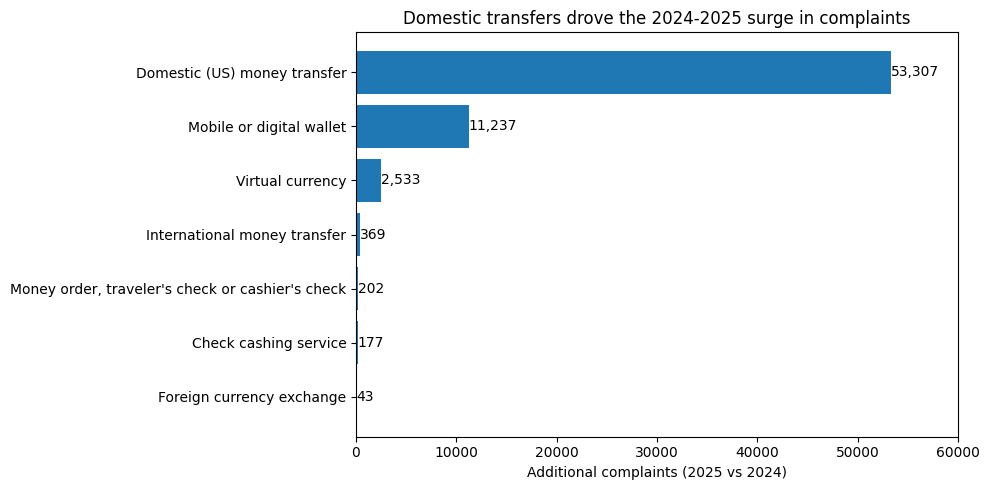

In [55]:
chart_data = by_sub.sort_values("change")
plt.figure(figsize=(10, 5))
bars = plt.barh(chart_data.index, chart_data["change"])
plt.bar_label(bars, fmt="{:,.0f}")
plt.xlim(0, 60000)
plt.title("Domestic transfers drove the 2024-2025 surge in complaints")
plt.xlabel("Additional complaints (2025 vs 2024)")
plt.tight_layout()
plt.show()

Complaints rose from 16,751 in 2024 to 84,619 in 2025 (about 5 times as many). Domestic money transfers account for 78.5% of the increase and digital wallets for 16.6%; all other sub-products barely changed.

Next: which companies drove the growth in these two sub-products?

In [56]:
domestic = complaints[complaints["Sub-product"] == "Domestic (US) money transfer"]
domestic_comp_year = domestic.groupby(["Company", "year"]).size().unstack().fillna(0).astype(int)
domestic_comp_year["change"] = domestic_comp_year[2025] - domestic_comp_year[2024]
domestic_comp_year["share_of_increase"] = round(domestic_comp_year["change"] / domestic_comp_year["change"].sum() * 100, 2)
domestic_comp_year = domestic_comp_year.sort_values("change", ascending=False)
domestic_comp_year.head(10)

year,2024,2025,change,share_of_increase
Company,,,,
"Block, Inc.",235,33665,33430,62.71
"Early Warning Services, LLC",225,17747,17522,32.87
Chime Financial Inc,82,796,714,1.34
"BANK OF AMERICA, NATIONAL ASSOCIATION",467,835,368,0.69
"Paypal Holdings, Inc",407,670,263,0.49
JPMORGAN CHASE & CO.,666,895,229,0.43
WELLS FARGO & COMPANY,528,741,213,0.40
ROBINHOOD MARKETS INC.,61,137,76,0.14
CAPITAL ONE FINANCIAL CORPORATION,95,164,69,0.13


In [57]:
mobile_digital_wallet = complaints[complaints["Sub-product"] == "Mobile or digital wallet"]
wallet_comp_year = mobile_digital_wallet.groupby(["Company", "year"]).size().unstack().fillna(0).astype(int)
wallet_comp_year["change"] = wallet_comp_year[2025] - wallet_comp_year[2024]
wallet_comp_year["share_of_increase"] = round(wallet_comp_year["change"] / wallet_comp_year["change"].sum() * 100, 2)
wallet_comp_year = wallet_comp_year.sort_values("change", ascending=False)
wallet_comp_year.head(10)

year,2024,2025,change,share_of_increase
Company,,,,
"Block, Inc.",1415,7308,5893,52.44
"Paypal Holdings, Inc",2255,4132,1877,16.70
"Early Warning Services, LLC",224,1534,1310,11.66
Chime Financial Inc,284,724,440,3.92
JPMORGAN CHASE & CO.,235,587,352,3.13
WELLS FARGO & COMPANY,225,480,255,2.27
"BANK OF AMERICA, NATIONAL ASSOCIATION",127,328,201,1.79
ROBINHOOD MARKETS INC.,107,262,155,1.38
"SOFI TECHNOLOGIES, INC.",15,69,54,0.48


**Q1 answer.** Block, Inc. (Cash App) accounts for 62.7% of the domestic-transfer increase, and together with Early Warning Services (Zelle) for 95.6%. Across both sub-products, Block alone accounts for 57.9% of the entire surge, and Block plus Early Warning for 85.7%.

These are complaint counts, not rates: they show where complaints grew, not that service quality declined. Larger apps have more users and therefore more complaints.

## 4. Q2: What went wrong, and did it change?

Because 2025 has 5 times as many complaints as 2024, issues are compared as shares of each year's complaints, not raw counts.

In [58]:
issue_year = complaints.groupby(["Issue", "year"]).size().unstack().fillna(0).astype(int)
issue_share = round(issue_year / issue_year.sum() * 100, 2)
issue_share = issue_share.sort_values(2025, ascending=False)
issue_share.head(10)

year,2024,2025
Issue,,
Other transaction problem,17.95,63.69
Fraud or scam,36.85,13.21
Unauthorized transactions or other transaction problem,9.91,6.80
Trouble accessing funds in your mobile or digital wallet,8.15,3.59
Money was not available when promised,9.58,2.87
Other service problem,3.25,2.44
Confusing or missing disclosures,2.15,2.33
"Managing, opening, or closing your mobile wallet account",4.53,2.10
Unexpected or other fees,1.95,0.76


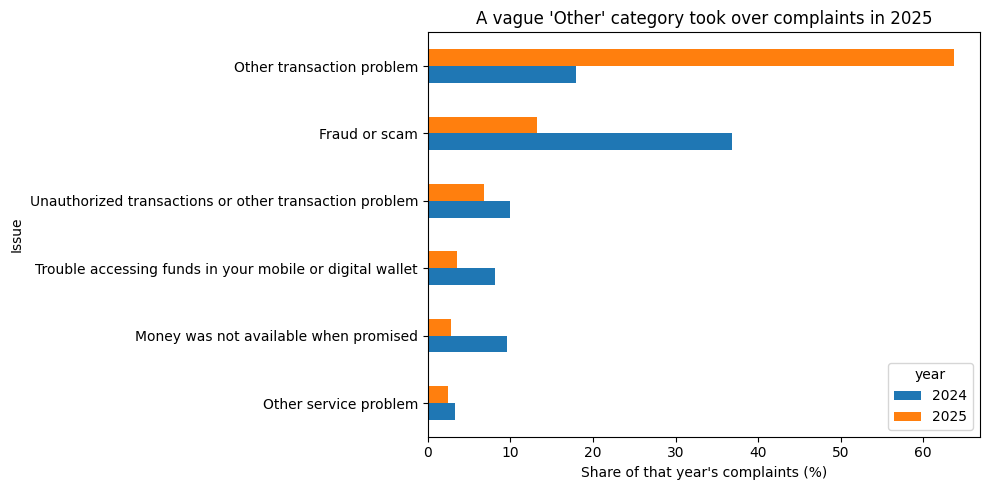

In [59]:
top_issues = issue_share.head(6).sort_values(2025)
top_issues.plot(kind="barh", figsize=(10, 5))
plt.title("A vague 'Other' category took over complaints in 2025")
plt.xlabel("Share of that year's complaints (%)")
plt.tight_layout()
plt.show()

Is the growth of "Other transaction problem" the same story as the domestic-transfer surge? Share of 2025 "Other" complaints that were domestic transfers, and share of 2025 domestic transfers labelled "Other":

In [60]:
check = complaints[(complaints["year"] == 2025) & (complaints["Sub-product"] == "Domestic (US) money transfer") & (complaints["Issue"] == "Other transaction problem")]
print(round(len(check) / issue_year.loc["Other transaction problem", 2025] * 100, 2))
print(round(len(check) / by_sub.loc["Domestic (US) money transfer", 2025] * 100, 2))

94.82
88.32


"Other transaction problem" grew from 18.0% of complaints in 2024 to 63.7% in 2025, while fraud fell from 36.9% to 13.2% as a share. 94.8% of the 2025 "Other" complaints were domestic transfers, and 88.3% of 2025 domestic-transfer complaints carry this vague label, so for the biggest part of the surge the data cannot say what actually went wrong.

Digital wallets, by contrast:

In [61]:
wallet_issue_year = mobile_digital_wallet.groupby(["Issue", "year"]).size().unstack().fillna(0).astype(int)
wallet_issue_share = round(wallet_issue_year / wallet_issue_year.sum() * 100, 2)
wallet_issue_share = wallet_issue_share.sort_values(2025, ascending=False)
print("Other transaction problem" in wallet_issue_share.index)
wallet_issue_share.head(10)

False


year,2024,2025
Issue,,
Unauthorized transactions or other transaction problem,28.07,33.57
Fraud or scam,30.49,29.04
Trouble accessing funds in your mobile or digital wallet,23.10,17.71
"Managing, opening, or closing your mobile wallet account",12.82,10.34
Confusing or missing disclosures,1.69,4.50
Confusing or misleading advertising or marketing,0.83,1.69
Unexpected or other fees,1.32,1.63
Problem adding money,1.35,1.14
"Overdraft, savings, or rewards features",0.32,0.37


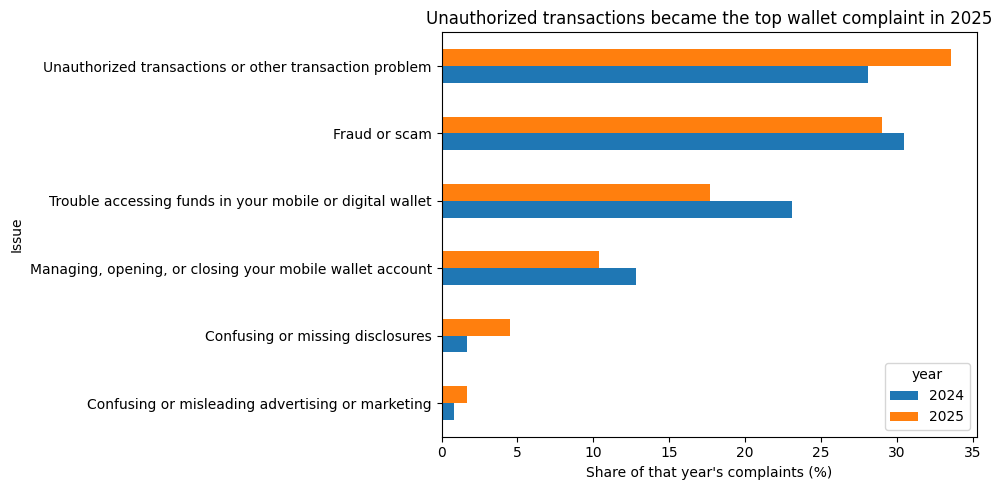

In [62]:
top_issues_wallet = wallet_issue_share.head(6).sort_values(2025)
top_issues_wallet.plot(kind="barh", figsize=(10, 5))
plt.title("Unauthorized transactions became the top wallet complaint in 2025")
plt.xlabel("Share of that year's complaints (%)")
plt.tight_layout()
plt.show()

**Q2 answer.** Overall, a vague catch-all label came to dominate complaints, almost entirely because of domestic transfers. Digital-wallet complaints never use that label and are more specific: in 2025, unauthorized transactions (33.6%, up from 28.1%) and fraud or scams (29.0%) made up 62.6% of wallet complaints. Most wallet complaints are about customers losing money, either without their permission or through scams.

## 5. Q3: How do companies handle complaints?

Timeliness (was the response on time?) and outcome (how was the complaint closed?) are separate fields:

In [63]:
complaints.groupby(["Company response to consumer", "Timely response?"]).size().unstack().fillna(0).astype(int)

Timely response?,No,Yes
Company response to consumer,,
Closed with explanation,1209,94492
Closed with monetary relief,39,3411
Closed with non-monetary relief,5,2051
In progress,0,2
Untimely response,161,0


98.6% of complaints received a timely response. Of the 1,414 late ones, most were still closed (1,209 with an explanation); 161 are recorded as "Untimely response".

To get reliable rates, companies are compared only if they have at least 100 complaints:

In [64]:
company_counts = complaints["Company"].value_counts()
companies_100_complaints = company_counts[company_counts >= 100]
big = complaints[complaints["Company"].isin(companies_100_complaints.index)]
print(len(companies_100_complaints))
print(len(big))

40
96998


In [65]:
timely = big.groupby(["Company", "Timely response?"]).size().unstack().fillna(0).astype(int)
timely["timely_rate"] = round(timely["Yes"] / (timely["Yes"] + timely["No"]) * 100, 2)
timely = timely.sort_values("timely_rate")
timely.head(10)

Timely response?,No,Yes,timely_rate
Company,,,
Sigue Corp.,95,128,57.40
Chime Inc.,34,129,79.14
Google Compare Credit Cards Inc.,30,160,84.21
ROBINHOOD MARKETS INC.,201,1359,87.12
"Ria Envia, LLC",10,102,91.07
TransferWise Ltd,32,654,95.34
"Blockchain.com, Inc.",9,208,95.85
AMERICAN EXPRESS COMPANY,2,108,98.18
"Remitly, Inc.",5,331,98.51


The 40 companies cover 96,998 complaints (95.7% of the total). Sigue Corp. answered only 57.4% of its complaints on time and Chime Inc. 79.1%, against 98.6% overall. (Chime appears under two CFPB company names, Chime Inc. and Chime Financial Inc, both active in both years, so they are analyzed separately as listed.)

**Relief rate** = complaints closed with monetary or non-monetary relief divided by all complaints except "In progress". Untimely responses count as no relief, to reflect the customer's experience.

In [66]:
big_closed = big[big["Company response to consumer"] != "In progress"].copy()
big_closed["relief"] = big_closed["Company response to consumer"].isin(["Closed with monetary relief", "Closed with non-monetary relief"])
relief_table = big_closed.groupby(["Company", "relief"]).size().unstack().fillna(0).astype(int)
relief_table["relief_rate"] = round(relief_table[True] / (relief_table[True] + relief_table[False]) * 100, 2)
relief_table = relief_table.sort_values("relief_rate")
print(len(relief_table[relief_table["relief_rate"] == 0]))
relief_table.tail(10)

9


relief,False,True,relief_rate
Company,,,
TD BANK US HOLDING COMPANY,222,68,23.45
"BANK OF AMERICA, NATIONAL ASSOCIATION",1931,597,23.62
"HUNTINGTON NATIONAL BANK, THE",87,27,23.68
SYNCHRONY FINANCIAL,109,35,24.31
AMERICAN EXPRESS COMPANY,81,29,26.36
"Paypal Holdings, Inc",6078,2472,28.91
DISCOVER BANK,136,56,29.17
MONEYGRAM PAYMENT SYSTEMS WORLDWIDE INC,286,135,32.07
ALLY FINANCIAL INC.,108,51,32.08


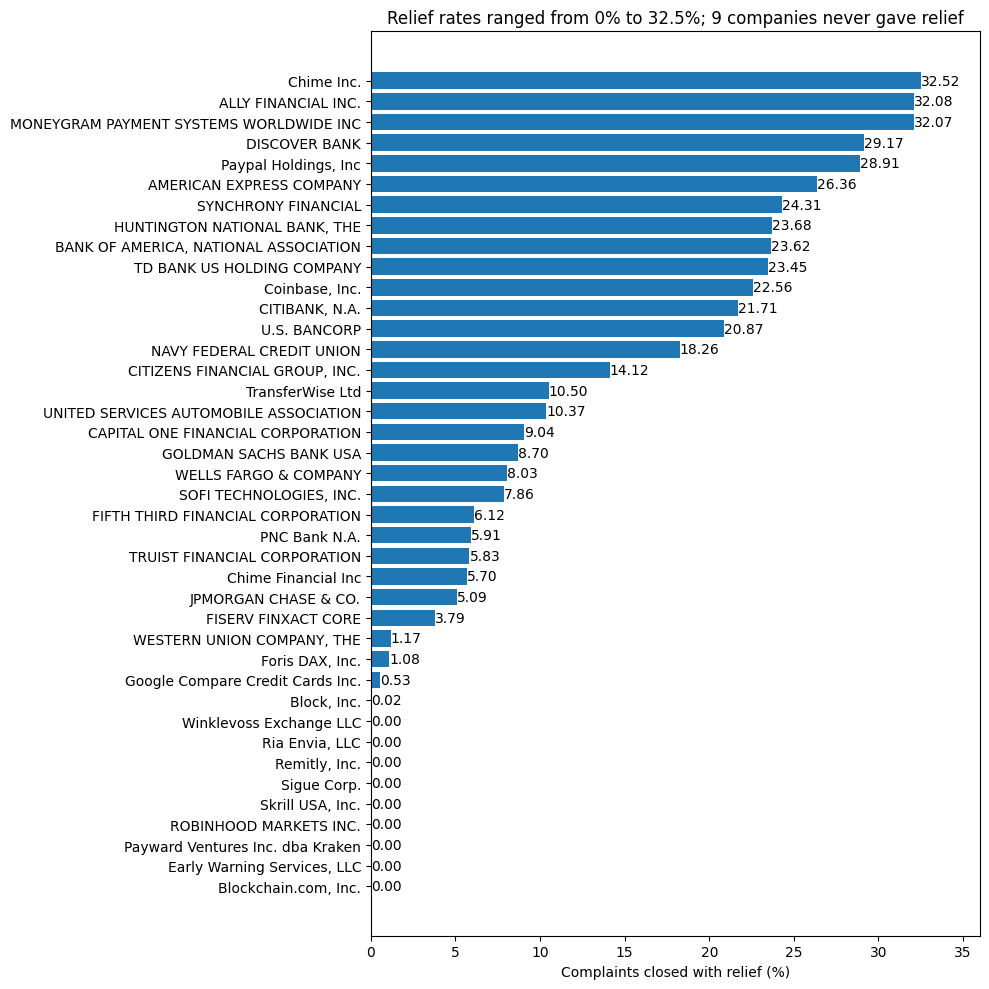

In [67]:
plt.figure(figsize=(10, 10))
bars = plt.barh(relief_table.index, relief_table["relief_rate"])
plt.bar_label(bars, fmt="{:.2f}")
plt.xlim(0, 36)
plt.title("Relief rates ranged from 0% to 32.5%; 9 companies never gave relief")
plt.xlabel("Complaints closed with relief (%)")
plt.tight_layout()
plt.show()

**Q3 answer.** Nearly all companies responded on time, with Sigue Corp. and Chime Inc. as clear outliers. Relief rates ranged from 0% to 32.5%: 9 of the 40 companies never closed a complaint with relief, and Block and Early Warning, the two companies behind the surge, closed only 7 of about 64,700 complaints with relief. Chime Inc. was slow but the most likely to give relief (32.5%).

## 6. Limitations

The data shows where complaints grew, not why: there is no data on user numbers, marketing or CFPB process changes.

Complaint counts are not rates: larger companies have more customers and therefore more complaints.

Response types (e.g. "Closed with monetary relief") are selected by the companies themselves. A 2015 federal audit found that the CFPB did not review all of these selections to check that they matched its definitions.

"No tag" means the consumer did not report being an older American or servicemember, not that they are not one.

Percentages may not total exactly 100% due to rounding.